# 02 — Étiquettes radar : calibrer la détection d'eau

**Objectifs**
1. Comprendre le comportement de la détection par changement radar (`sentinelle_lome.labels.flood_labels`).
2. Montrer l'effet du **masque HAND** et de la **concordance des deux passes**.
3. Fournir la procédure pour calibrer les seuils sur les vraies scènes de Lomé.

> **Avertissement essentiel.** La partie 1 utilise une scène **entièrement fictive** avec une vérité terrain connue. Ses scores illustrent la **méthode** et ne disent **rien** sur la performance à Lomé. Les seuils de `projet.yaml` restent « À CALIBRER » tant que la partie 2 n'a pas tourné sur de vraies données avec une référence (Charte, drones ANPC).

In [1]:
import sys, json, math
from pathlib import Path

# Racine du dépôt : fonctionne que le notebook soit lancé depuis notebooks/ ou depuis la racine.
RACINE = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RACINE / "src"))  # repli si `pip install -e .` n'a pas été fait

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sentinelle_lome.config import charger_config, charger_evenements

cfg = charger_config()
evts = charger_evenements()
print("Racine du dépôt :", RACINE)

Racine du dépôt : /home/claude/sentinelle-lome


In [2]:
from sentinelle_lome.labels.flood_labels import concordance_passes, detecter_eau, metriques_masques, vers_db
rng = np.random.default_rng(42)

## 1. Scène synthétique à vérité connue (FICTIF)

On construit 200×200 pixels avec :
- une **cuvette inondée** (vérité terrain connue, basse altitude relative) ;
- une zone d'**ombre radar** sombre aux deux dates (pas de changement) ;
- une zone de **faux changement** (par exemple sol modifié) sur terrain élevé, qui imite une baisse de rétrodiffusion ;
- un **bruit de speckle** multiplicatif, indépendant entre les images.

In [3]:
N = 200
yy, xx = np.mgrid[0:N, 0:N]

vrai = ((xx - 100) ** 2 / 60**2 + (yy - 110) ** 2 / 35**2) < 1           # eau d'inondation (vérité)
hand = 0.15 * np.sqrt((xx - 100) ** 2 + (yy - 110) ** 2)                 # HAND fictif : bas au centre
ombre = (xx > 150) & (yy < 50)                                            # sombre aux deux dates
faux = (xx < 40) & (yy > 150)                                             # faux changement, terrain élevé
hand = np.where(faux, 30.0, hand)
hand = np.where(ombre, 25.0, hand)

def scene(vrai, avec_changement_faux=True, graine=0, looks=5):
    r = np.random.default_rng(graine)
    base_pre = np.full((N, N), 0.12)                  # ~ -9,2 dB en intensité linéaire
    base_post = base_pre.copy()
    base_post[vrai] = 0.01                            # eau : ~ -20 dB
    base_pre[ombre] = base_post[ombre] = 0.01         # ombre : sombre avant ET après
    if avec_changement_faux:
        base_post[faux] = 0.12 * 0.3                  # baisse de ~ -5 dB sans eau
    speckle = lambda: r.gamma(looks, 1 / looks, (N, N))
    return base_pre * speckle(), base_post * speckle()

def lissage_boite(a, k=3):
    # moyenne glissante k×k sur l'intensité linéaire, pour atténuer le speckle
    p = k // 2
    ap = np.pad(a, p, mode="reflect")
    return sum(ap[i:i + a.shape[0], j:j + a.shape[1]] for i in range(k) for j in range(k)) / (k * k)

pre_a, post_a = scene(vrai, graine=1)
pre_db, post_db = vers_db(lissage_boite(pre_a)), vers_db(lissage_boite(post_a))
print("Pixels d'eau (vérité) :", int(vrai.sum()), "/", N * N)

Pixels d'eau (vérité) : 6571 / 40000


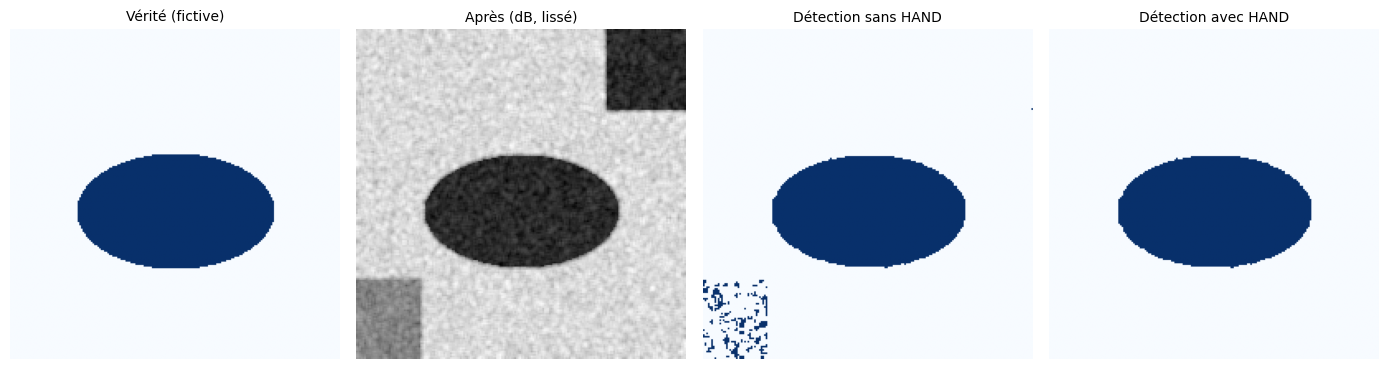

,precision,rappel,f1,iou
sans HAND,0.943,0.962,0.952,0.909
avec HAND,1.000,0.962,0.980,0.962


In [4]:
sans_hand = detecter_eau(pre_db, post_db, seuil_delta_db=cfg["labels"]["seuil_delta_db"],
                         seuil_post_db=cfg["labels"]["seuil_post_db"])
avec_hand = detecter_eau(pre_db, post_db, seuil_delta_db=cfg["labels"]["seuil_delta_db"],
                         seuil_post_db=cfg["labels"]["seuil_post_db"], hand=hand, hand_max_m=cfg["labels"]["hand_max_m"])

fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, img, titre in zip(axes, [vrai, post_db, sans_hand, avec_hand],
                          ["Vérité (fictive)", "Après (dB, lissé)", "Détection sans HAND", "Détection avec HAND"]):
    ax.imshow(img, cmap="gray" if img is post_db else "Blues")
    ax.set_title(titre, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

res = pd.DataFrame({"sans HAND": metriques_masques(sans_hand, vrai), "avec HAND": metriques_masques(avec_hand, vrai)}).T
res.round(3)

**Lecture (sur la scène fictive uniquement).** Le masque HAND retire le faux changement situé sur terrain élevé et augmente la précision. L'ombre n'est pas détectée car elle est sombre aux **deux** dates : c'est l'intérêt de la détection par *changement* plutôt que par simple seuil sur l'image « après ».

### Sensibilité aux seuils

On balaie `seuil_delta_db` et `seuil_post_db` et on mesure le F1 contre la vérité fictive. Sur de vraies données, **la même grille se calcule contre la référence** (contours Charte, drones), jamais contre les étiquettes elles-mêmes.

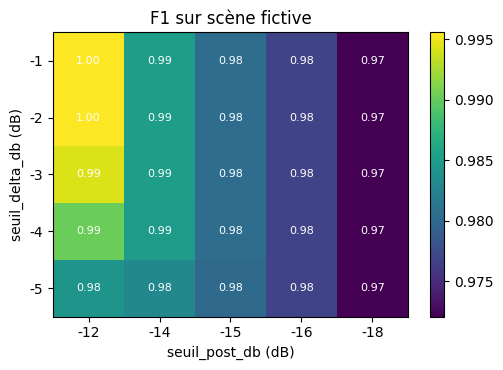

In [5]:
deltas = [-1, -2, -3, -4, -5]
posts = [-12, -14, -15, -16, -18]
grille = np.array([[metriques_masques(detecter_eau(pre_db, post_db, d, p, hand=hand, hand_max_m=cfg["labels"]["hand_max_m"]), vrai)["f1"]
                    for p in posts] for d in deltas])

fig, ax = plt.subplots(figsize=(5.2, 3.8))
im = ax.imshow(grille, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(posts)), posts); ax.set_yticks(range(len(deltas)), deltas)
ax.set_xlabel("seuil_post_db (dB)"); ax.set_ylabel("seuil_delta_db (dB)")
ax.set_title("F1 sur scène fictive")
for i in range(len(deltas)):
    for j in range(len(posts)):
        ax.text(j, i, f"{grille[i, j]:.2f}", ha="center", va="center", color="w", fontsize=8)
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

### Concordance des deux passes

Une seconde passe (orbite opposée) a une géométrie différente : speckle indépendant. L'étiquette « haute confiance » exige que **les deux passes détectent l'eau** (`concordance_passes`).

Pour que l'effet soit visible, on utilise ici un **speckle plus fort** (2 vues, **sans lissage**). Avec le lissage de l'exemple précédent, chaque passe était déjà presque parfaite et la concordance n'apportait rien : elle ne sert que si le bruit est important.

In [6]:
pre_a2, post_a2 = scene(vrai, graine=1, looks=2)
pre_b2, post_b2 = scene(vrai, graine=2, looks=2)
mask_a = detecter_eau(vers_db(pre_a2), vers_db(post_a2), hand=hand)
mask_b = detecter_eau(vers_db(pre_b2), vers_db(post_b2), hand=hand)
mask_conc = concordance_passes(mask_a, mask_b)

comparaison = pd.DataFrame({
    "passe A seule": metriques_masques(mask_a, vrai),
    "passe B seule": metriques_masques(mask_b, vrai),
    "concordance A∧B": metriques_masques(mask_conc, vrai),
}).T
comparaison.round(3)

,precision,rappel,f1,iou
passe A seule,0.758,0.934,0.837,0.720
passe B seule,0.759,0.935,0.838,0.721
concordance A∧B,0.974,0.873,0.920,0.853


**Lecture (fictive).** Dans cet exemple bruité, la concordance **augmente la précision et diminue le rappel** par rapport à chaque passe seule : c'est le compromis voulu pour une étiquette « haute confiance ». Les cellules détectées par une seule passe forment la confiance « moyenne » (`docs/04`).

**Limite.** La concordance ne corrige que les erreurs **aléatoires** (le speckle). Une confusion **systématique** (ombre, faux changement, route) apparaît dans les deux passes et exige le masque HAND ou d'autres masques.

## 2. Procédure sur les vraies scènes

Prérequis : les exports de `python -m sentinelle_lome.ingestion.gee_export` dans `data/raw/` (fichiers `s1_<événement>_<passe>_<avant|apres>.tif`), et `rasterio` installé.

**Hypothèse à vérifier** : les valeurs exportées depuis `COPERNICUS/S1_GRD` sont censées être déjà en **dB** (échelle logarithmique) ; vérifier sur la fiche de la collection avant tout calcul. Dans ce cas, **ne pas** appliquer `vers_db`. Le composite médian est calculé sur ces valeurs en dB.

In [7]:
import glob

def charger_paire(evenement_id: str, passe3: str, dossier: Path = RACINE / "data" / "raw"):
    """Lit (avant, après) en bande 1 = VV. Retourne None si les fichiers sont absents."""
    import rasterio
    f_av = dossier / f"s1_{evenement_id}_{passe3}_avant.tif"
    f_ap = dossier / f"s1_{evenement_id}_{passe3}_apres.tif"
    if not (f_av.exists() and f_ap.exists()):
        return None
    with rasterio.open(f_av) as a, rasterio.open(f_ap) as b:
        return a.read(1).astype("float32"), b.read(1).astype("float32")

fichiers = glob.glob(str(RACINE / "data" / "raw" / "s1_*.tif"))
if not fichiers:
    print("Aucun export Sentinel-1 trouvé dans data/raw/ : partie 2 non exécutée (normal avant l'ingestion).")
else:
    try:
        import rasterio  # noqa: F401
    except ImportError:
        print("rasterio n'est pas installé : pip install -e '.[notebooks]'")
    else:
        for e in evts:
            if e["date_pic"] is None:
                continue
            paires = {p: charger_paire(e["id"], p) for p in ("asc", "des")}
            if any(v is None for v in paires.values()):
                print(f"{e['id']} : paires asc/des incomplètes, ignoré")
                continue
            masques = {p: detecter_eau(av, ap, cfg["labels"]["seuil_delta_db"], cfg["labels"]["seuil_post_db"])
                       for p, (av, ap) in paires.items()}   # ajouter hand=... une fois le HAND calculé
            conc = concordance_passes(masques["asc"], masques["des"])
            print(f"{e['id']} : eau asc={masques['asc'].mean():.3%}, des={masques['des'].mean():.3%}, concordance={conc.mean():.3%}")

Aucun export Sentinel-1 trouvé dans data/raw/ : partie 2 non exécutée (normal avant l'ingestion).


### Calibration sur référence réelle (à faire quand elle est disponible)

1. Rastériser la référence (contours Charte ou cartes drone) sur la grille radar.
2. Rejouer la grille de sensibilité ci-dessus avec `metriques_masques(pred, reference)`.
3. Choisir les seuils sur un sous-ensemble d'événements, **évaluer sur un autre** (par exemple apprentissage 2020, test 2026).
4. Reporter les seuils retenus **et** les scores dans `configs/projet.yaml` et `docs/04`, en retirant la mention « À CALIBRER » seulement alors.
5. Documenter le biais de sous-détection en ville dense.

**Prochaine étape** : `03_variables_pluie.ipynb`.